<a href="https://colab.research.google.com/github/cns-biotech/tcga-skcm-immune-subtypes/blob/main/skcm_immune_subtypes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np
from google.colab import drive
drive.mount('/content/drive')

WORK = "/content/drive/MyDrive/skcm_project"
!mkdir -p "{WORK}"

!wget -q -O "{WORK}/HiSeqV2.gz" "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/TCGA.SKCM.sampleMap/HiSeqV2.gz"
!wget -q -O "{WORK}/SKCM_survival.txt" "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/survival%2FSKCM_survival.txt"
!wget -q -O "{WORK}/mfp_signatures.gmt" "https://raw.githubusercontent.com/BostonGene/MFP/master/signatures/gene_signatures.gmt"
!ls -lh "{WORK}"

expr = pd.read_csv(f"{WORK}/HiSeqV2.gz", sep="\t", index_col=0)
surv = pd.read_csv(f"{WORK}/SKCM_survival.txt", sep="\t")

sigs = {}
for line in open(f"{WORK}/mfp_signatures.gmt"):
    p = line.rstrip("\n").split("\t")
    sigs[p[0]] = [g for g in p[2:] if g]

print("экспрессия:", expr.shape)
print(expr.iloc[:3, :3])
print("выживаемость:", surv.shape, list(surv.columns))
print("сигнатур:", len(sigs))

Mounted at /content/drive
total 25M
-rw------- 1 root root  25M Apr  8  2021 HiSeqV2.gz
-rw------- 1 root root 2.6K Nov  8 17:22 mfp_signatures.gmt
-rw------- 1 root root  24K Apr  8  2021 SKCM_survival.txt
экспрессия: (20530, 474)
           TCGA-YD-A89C-06  TCGA-Z2-AA3V-06  TCGA-EB-A3Y6-01
sample                                                      
ARHGEF10L           9.1174          10.4428           9.5005
HIF3A               4.8009           3.2481           2.8755
RNF17               0.0000           0.0000           0.0000
выживаемость: (479, 11) ['sample', '_PATIENT', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Redaction']
сигнатур: 29


In [2]:
# какие гены сигнатур есть в матрице
all_sig_genes = sorted({g for gs in sigs.values() for g in gs})
missing = [g for g in all_sig_genes if g not in expr.index]
print("генов в сигнатурах:", len(all_sig_genes), "не найдено:", len(missing))
print(missing)

# типы образцов по коду в конце штрих-кода
codes = pd.Series([s.split("-")[3] for s in expr.columns], index=expr.columns)
print(codes.value_counts())

# z-оценки по каждому гену через образцы
sub = expr.loc[[g for g in all_sig_genes if g in expr.index]]
sub = sub[sub.std(axis=1) > 0]
z = sub.sub(sub.mean(axis=1), axis=0).div(sub.std(axis=1), axis=0)

# балл набора = среднее z по его генам
scores = pd.DataFrame({name: z.loc[[g for g in genes if g in z.index]].mean()
                       for name, genes in sigs.items()})
scores.index.name = "sample"
print("матрица баллов:", scores.shape)
print(scores.iloc[:3, :4].round(2))
print("пропусков:", int(scores.isna().sum().sum()))
scores.to_csv(f"{WORK}/mfp_scores.csv")

генов в сигнатурах: 257 не найдено: 5
['CXCL8', 'TRAC', 'TRBC1', 'TRBC2', 'VSIR']
06    368
01    104
07      1
11      1
Name: count, dtype: int64
матрица баллов: (474, 29)
                 MHCI  MHCII  Coactivation_molecules  Effector_cells
sample                                                              
TCGA-YD-A89C-06 -2.76  -1.49                   -1.13           -1.22
TCGA-Z2-AA3V-06  0.61   1.27                    0.77            1.18
TCGA-EB-A3Y6-01  0.57  -0.19                   -0.26            0.03
пропусков: 0


In [4]:
alias = {"CXCL8": "IL8", "VSIR": "C10orf54",
         "TRAC": None, "TRBC1": None, "TRBC2": None}
for new, old in alias.items():
    print(new, "старое имя:", old, "есть в матрице:", old in expr.index if old else "—")

tumor = [s for s in expr.columns if s.split("-")[3] != "11"]
expr_t = expr[tumor]
print("образцов опухоли:", expr_t.shape[1])


sigs_fixed = {}
for name, genes in sigs.items():
    out = []
    for g in genes:
        if g in expr_t.index:
            out.append(g)
        elif alias.get(g) and alias[g] in expr_t.index:
            out.append(alias[g])
    sigs_fixed[name] = out

used = sorted({g for gs in sigs_fixed.values() for g in gs})
sub = expr_t.loc[used]
sub = sub[sub.std(axis=1) > 0]
z = sub.sub(sub.mean(axis=1), axis=0).div(sub.std(axis=1), axis=0)
scores = pd.DataFrame({n: z.loc[[g for g in gs if g in z.index]].mean()
                       for n, gs in sigs_fixed.items()})
scores.index.name = "sample"
print("баллы:", scores.shape, "использовано генов:", len(used))
scores.to_csv(f"{WORK}/mfp_scores.csv")

CXCL8 старое имя: IL8 есть в матрице: True
VSIR старое имя: C10orf54 есть в матрице: True
TRAC старое имя: None есть в матрице: —
TRBC1 старое имя: None есть в матрице: —
TRBC2 старое имя: None есть в матрице: —
образцов опухоли: 473
баллы: (473, 29) использовано генов: 254


cluster
1    163
2     96
3    101
4    113
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


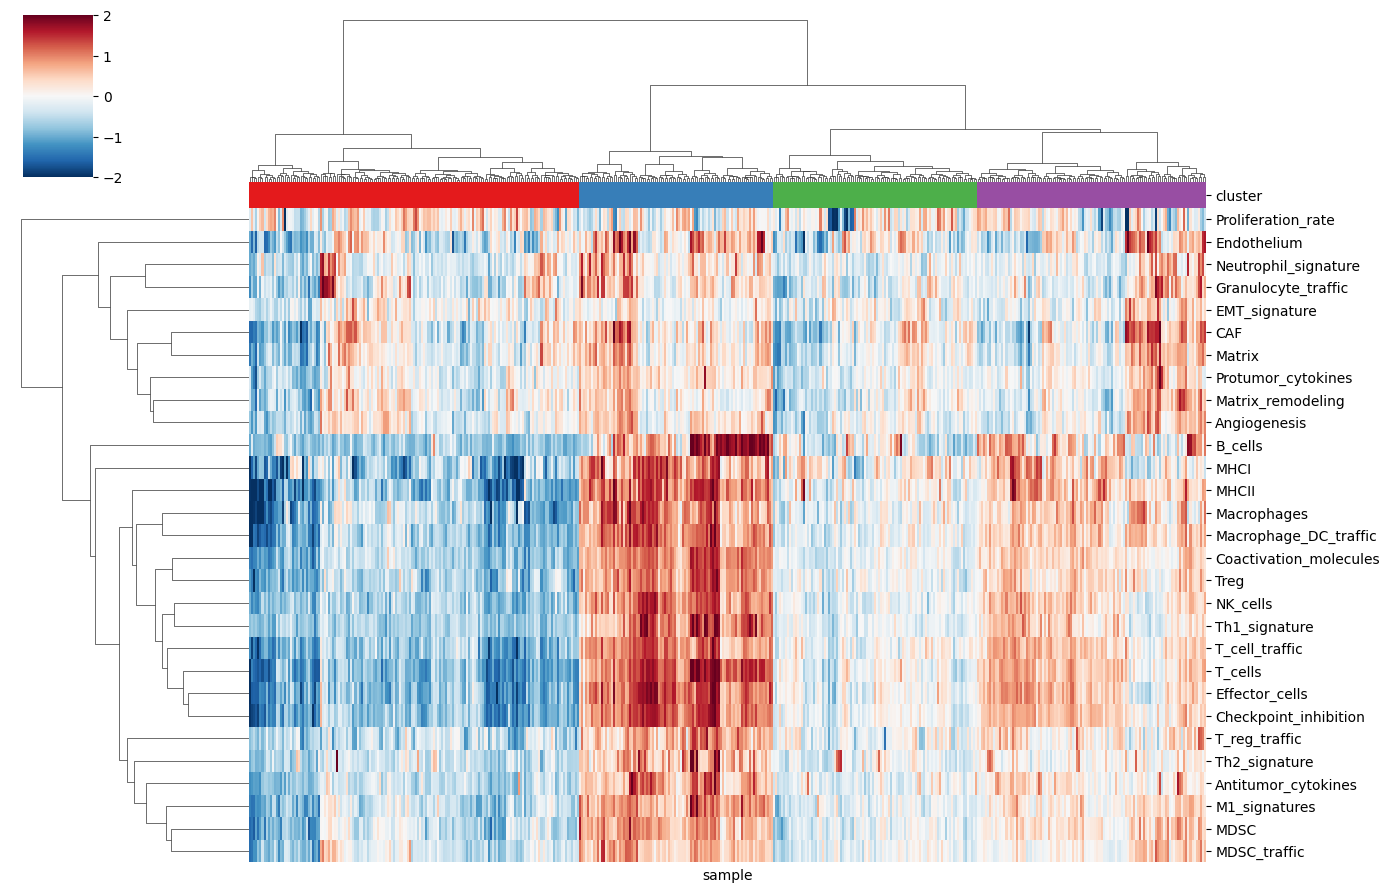

cluster                    1     2     3     4
MHCI                   -0.81  0.92  0.06  0.33
MHCII                  -1.01  1.12 -0.04  0.55
Coactivation_molecules -0.70  0.97 -0.17  0.33
Effector_cells         -0.94  1.17 -0.09  0.44
T_cell_traffic         -0.83  0.94 -0.04  0.45
NK_cells               -0.71  0.99 -0.18  0.34
T_cells                -1.00  1.25 -0.09  0.47
B_cells                -0.70  0.99 -0.18  0.33
M1_signatures          -0.52  0.82 -0.21  0.24
Th1_signature          -0.66  1.02 -0.19  0.27
Antitumor_cytokines    -0.52  0.75 -0.13  0.23
Checkpoint_inhibition  -0.91  1.12 -0.10  0.46
Treg                   -0.69  0.93 -0.13  0.33
T_reg_traffic          -0.48  0.68 -0.12  0.22
Neutrophil_signature   -0.14  0.39 -0.20  0.06
Granulocyte_traffic    -0.16  0.39 -0.24  0.11
MDSC                   -0.51  0.74 -0.23  0.32
MDSC_traffic           -0.38  0.60 -0.18  0.19
Macrophages            -0.77  0.96 -0.14  0.42
Macrophage_DC_traffic  -0.79  1.00 -0.17  0.45
Th2_signature

In [5]:
import seaborn as sns, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster

X = scores.clip(-2, 2)
Z = linkage(X, method="ward")
clusters = pd.Series(fcluster(Z, t=4, criterion="maxclust"),
                     index=scores.index, name="cluster")
print(clusters.value_counts().sort_index())

colors = clusters.map({1: "#e41a1c", 2: "#377eb8", 3: "#4daf4a", 4: "#984ea3"})
g = sns.clustermap(X.T, col_linkage=Z, row_cluster=True,
                   cmap="RdBu_r", center=0, figsize=(14, 9),
                   xticklabels=False, col_colors=colors)
g.savefig(f"{WORK}/fig_heatmap.png", dpi=150)
plt.show()

profile = scores.groupby(clusters).mean().T.round(2)
print(profile)

cluster
1    163
2     96
3    101
4    113
Name: count, dtype: int64
         immune  stroma
cluster                
1         -0.78   -0.16
2          1.00    0.30
3         -0.11   -0.15
4          0.37    0.11


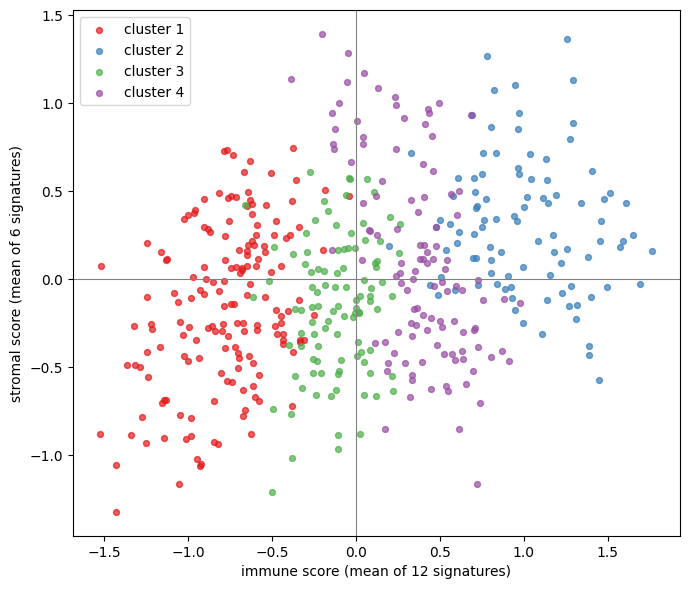

In [6]:
immune = ["MHCI", "MHCII", "Coactivation_molecules", "Effector_cells",
          "T_cell_traffic", "NK_cells", "T_cells", "B_cells",
          "M1_signatures", "Th1_signature", "Antitumor_cytokines",
          "Checkpoint_inhibition"]
stromal = ["CAF", "Matrix", "Matrix_remodeling", "Angiogenesis",
           "Endothelium", "EMT_signature"]

axes = pd.DataFrame({"immune": scores[immune].mean(axis=1),
                     "stroma": scores[stromal].mean(axis=1),
                     "cluster": clusters})
print(axes["cluster"].value_counts().sort_index())
print(axes.groupby("cluster")[["immune", "stroma"]].mean().round(2))

fig, ax = plt.subplots(figsize=(7, 6))
for c, col in zip([1, 2, 3, 4], ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3"]):
    s = axes[axes["cluster"] == c]
    ax.scatter(s["immune"], s["stroma"], s=18, alpha=0.7, c=col, label=f"cluster {c}")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("immune score (mean of 12 signatures)")
ax.set_ylabel("stromal score (mean of 6 signatures)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{WORK}/fig_axes.png", dpi=150)
plt.show()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
immune vs stroma: rho = 0.3 p = 2.8476305898940212e-11
образцов с выживаемостью: 457
                 count   sum
tme                         
Depleted           158  95.0
Immune-enriched     93  30.0
Immune-moderate    110  41.0
Intermediate        96  49.0


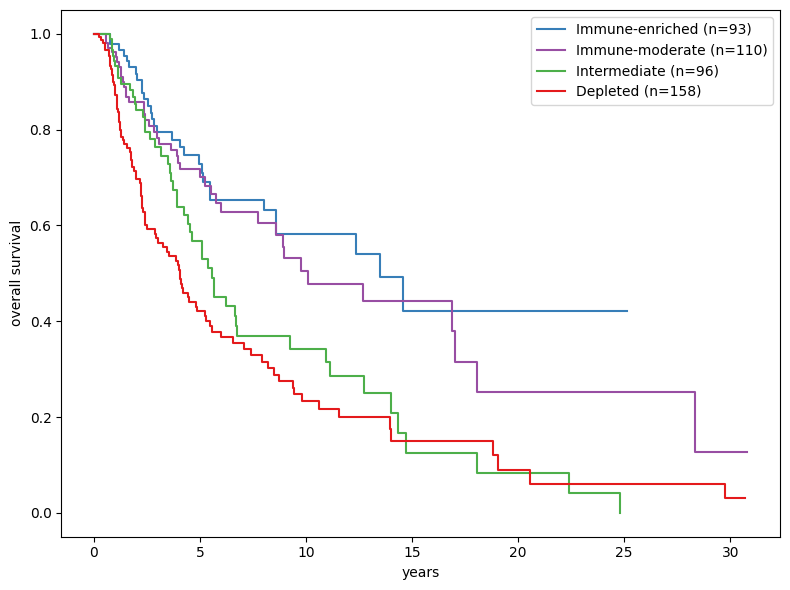

log-rank p = 1.644077512095863e-07


In [7]:
!pip -q install lifelines
from scipy.stats import spearmanr
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

rho, p = spearmanr(axes["immune"], axes["stroma"])
print("immune vs stroma: rho =", round(rho, 3), "p =", p)

names = {1: "Depleted", 3: "Intermediate", 4: "Immune-moderate", 2: "Immune-enriched"}
axes["tme"] = axes["cluster"].map(names)

s = surv.set_index("sample")[["OS", "OS.time"]]
d = axes.join(s, how="inner").dropna(subset=["OS", "OS.time"])
print("образцов с выживаемостью:", len(d))
print(d.groupby("tme")["OS"].agg(["count", "sum"]))

fig, ax = plt.subplots(figsize=(8, 6))
kmf = KaplanMeierFitter()
for c, col in zip([2, 4, 3, 1], ["#377eb8", "#984ea3", "#4daf4a", "#e41a1c"]):
    m = d["cluster"] == c
    kmf.fit(d.loc[m, "OS.time"] / 365.25, d.loc[m, "OS"],
            label=f"{names[c]} (n={int(m.sum())})")
    kmf.plot_survival_function(ax=ax, ci_show=False, color=col)
ax.set_xlabel("years")
ax.set_ylabel("overall survival")
plt.tight_layout()
plt.savefig(f"{WORK}/fig_survival.png", dpi=150)
plt.show()

res = multivariate_logrank_test(d["OS.time"], d["cluster"], d["OS"])
print("log-rank p =", res.p_value)

In [8]:
for c in [2, 4, 3, 1]:
    m = d["cluster"] == c
    kmf.fit(d.loc[m, "OS.time"] / 365.25, d.loc[m, "OS"])
    print(names[c], "медиана выживаемости, лет:",
          round(kmf.median_survival_time_, 1))

d[["immune", "stroma", "cluster", "tme"]].to_csv(f"{WORK}/skcm_tme_subtypes.csv")
print("сохранено")

Immune-enriched медиана выживаемости, лет: 13.5
Immune-moderate медиана выживаемости, лет: 10.1
Intermediate медиана выживаемости, лет: 5.6
Depleted медиана выживаемости, лет: 4.0
сохранено


In [9]:
!wget -q -O "{WORK}/SKCM_clinicalMatrix" "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/TCGA.SKCM.sampleMap/SKCM_clinicalMatrix"
from lifelines import CoxPHFitter

clin = pd.read_csv(f"{WORK}/SKCM_clinicalMatrix", sep="\t", index_col=0, low_memory=False)
c = clin[["pathologic_stage", "gender", "sample_type",
          "age_at_initial_pathologic_diagnosis"]].copy()
c["stage"] = c["pathologic_stage"].str.extract(r"Stage (IV|III|II|I)")[0]

cox = d.join(c, how="inner").rename(
    columns={"age_at_initial_pathologic_diagnosis": "age", "OS.time": "time"})
cox["time"] = cox["time"] / 365.25
cox["male"] = (cox["gender"] == "MALE").astype(int)
cox["metastatic"] = (cox["sample_type"] != "Primary Tumor").astype(int)

m = cox[["time", "OS", "immune", "age", "male", "metastatic", "stage"]].dropna()
m = pd.get_dummies(m, columns=["stage"], drop_first=True, dtype=float)
print("вошло в модель:", m.shape)

cph = CoxPHFitter()
cph.fit(m, duration_col="time", event_col="OS")
cph.print_summary(decimals=3)

вошло в модель: (411, 9)


<lifelines.CoxPHFitter: fitted with 411 total observations, 220 right-censored observations>
             duration col = 'time'
                event col = 'OS'
      baseline estimation = breslow
   number of observations = 411
number of events observed = 191
   partial log-likelihood = -925.920
         time fit was run = 2026-11-08 17:37:39 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
immune     -0.644     0.525     0.112          -0.863          -0.424               0.422               0.654
age         0.018     1.018     0.005           0.008           0.028               1.008               1.029
male        0.029     1.029     0.158          -0.282           0.339               0.754               1.403
metastatic -0.864     0.421     0.240          -1.335          -0.393               0.263               0.675
stage_II    0.022     1.022     0.220          -0.409           0.452               0.664               1.572
stage_III   0.558     1.747     0.202           0.162           0.954               1.176               2.595
stage_IV    1.389     4.010     0.353           0.697           2.081               2.007               8.011

            cmp to      z       p  -log2(p)
covariate                                  
immune       0.000 -5.751 <0.0005    26.748
age          0.000  3.579 <0.0005    11.500
male         0.000  0.180   0.857     0.223
metastatic   0.000 -3.598 <0.0005    11.605
stage_II     0.000  0.099   0.921     0.118
stage_III    0.000  2.764   0.006     7.453
stage_IV     0.000  3.933 <0.0005    13.538
---
Concordance = 0.703
Partial AIC = 1865.840
log-likelihood ratio test = 82.642 on 7 df
-log2(p) of ll-ratio test = 47.836

In [10]:
m2 = m.copy()
sd = m2["immune"].std()
m2["immune_z"] = m2["immune"] / sd
m2 = m2.drop(columns=["immune"])
print("sd иммунного балла:", round(sd, 3))

cph2 = CoxPHFitter()
cph2.fit(m2, duration_col="time", event_col="OS")
print(cph2.summary.loc["immune_z", ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]])

# 2. сколько кластеров говорят сами данные
from sklearn.metrics import silhouette_score
for k in range(2, 9):
    lab = fcluster(Z, t=k, criterion="maxclust")
    print(k, round(silhouette_score(X, lab), 3))

# 3. связь кластеров с типом образца и стадией
from scipy.stats import chi2_contingency
for col in ["sample_type", "stage"]:
    tab = pd.crosstab(cox["tme"], cox[col])
    print("\n", tab)
    print("chi2 p =", chi2_contingency(tab)[1])

sd иммунного балла: 0.719
exp(coef)              6.295813e-01
exp(coef) lower 95%    5.377348e-01
exp(coef) upper 95%    7.371154e-01
p                      8.870448e-09
Name: immune_z, dtype: float64
2 0.302
3 0.218
4 0.136
5 0.143
6 0.134
7 0.119
8 0.111

 sample_type      Additional Metastatic  Metastatic  Primary Tumor
tme                                                              
Depleted                             0         113             45
Immune-enriched                      0          81             12
Immune-moderate                      0          92             18
Intermediate                         1          66             28
chi2 p = 0.008791274840171283

 stage             I  II  III  IV
tme                             
Depleted         22  60   54   8
Immune-enriched  21  14   42   4
Immune-moderate  20  30   44   5
Intermediate     15  36   30   6
chi2 p = 0.02971604765296687


с выживаемостью: 457 после join с клиникой: 457
age пропусков: 0
gender пропусков: 0
sample_type пропусков: 1
stage пропусков: 46
хотя бы один пропуск: 47
The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'stage_III' failed the non-proportional test: p-value is 0.0280.

   Advice: with so few unique values (only 2), you can include `strata=['stage_III', ...]` in the
call in `.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification

Immune-enriched медиана: 13.5 ДИ: [8.0, inf] | 5-летняя выживаемость: 0.729
Immune-moderate медиана: 10.1 ДИ: [7.7, 17.0] | 5

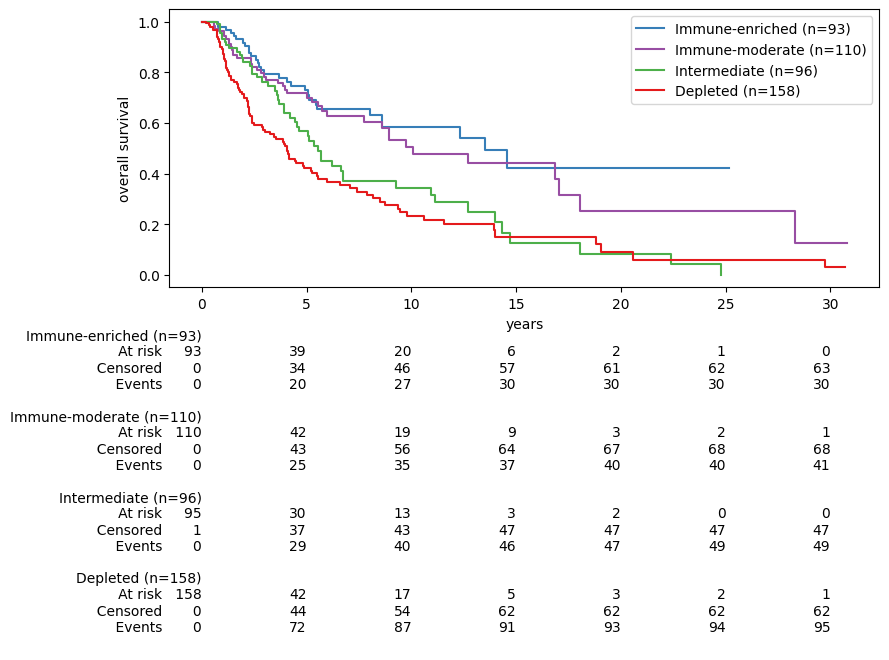

lifelines 0.30.3 | sklearn 1.6.1 | scipy 1.16.3 | pandas 2.2.3


In [11]:
# 5. откуда потери образцов
print("с выживаемостью:", len(d), "после join с клиникой:", len(cox))
for col in ["age", "gender", "sample_type", "stage"]:
    print(col, "пропусков:", int(cox[col].isna().sum()))
print("хотя бы один пропуск:",
      int(cox[["age", "gender", "sample_type", "stage"]].isna().any(axis=1).sum()))

# 4. проверка пропорциональности рисков
cph2.check_assumptions(m2, p_value_threshold=0.05, show_plots=False)

# 2. интервалы медиан, пятилетняя выживаемость, число в риске
from lifelines.utils import median_survival_times
from lifelines.plotting import add_at_risk_counts

fig, ax = plt.subplots(figsize=(9, 7))
fitters = []
for c, col in zip([2, 4, 3, 1], ["#377eb8", "#984ea3", "#4daf4a", "#e41a1c"]):
    mm = d["cluster"] == c
    k = KaplanMeierFitter(label=f"{names[c]} (n={int(mm.sum())})")
    k.fit(d.loc[mm, "OS.time"] / 365.25, d.loc[mm, "OS"])
    k.plot_survival_function(ax=ax, ci_show=False, color=col)
    ci = median_survival_times(k.confidence_interval_).values.round(1).tolist()[0]
    print(names[c], "медиана:", round(k.median_survival_time_, 1),
          "ДИ:", ci, "| 5-летняя выживаемость:", round(float(k.predict(5)), 3))
    fitters.append(k)
add_at_risk_counts(*fitters, ax=ax)
ax.set_xlabel("years"); ax.set_ylabel("overall survival")
plt.tight_layout()
plt.savefig(f"{WORK}/fig_survival.png", dpi=150)
plt.show()

import lifelines, sklearn, scipy
print("lifelines", lifelines.__version__, "| sklearn", sklearn.__version__,
      "| scipy", scipy.__version__, "| pandas", pd.__version__)

In [12]:
names = {1: "Low", 3: "Intermediate", 4: "High", 2: "Very high"}
axes["tme"] = axes["cluster"].map(names)
d["tme"] = d["cluster"].map(names)
axes[["immune", "stroma", "cluster", "tme"]].to_csv(f"{WORK}/skcm_tme_subtypes.csv")